# Madhava-Leibniz π calculation


This notebook is designed to be a live demonstration of Python fundamentals applied to calculating π using the [Madhava-Leibniz series](https://en.wikipedia.org/wiki/Approximations_of_%CF%80#Middle_Ages)

The approximation is simple:

$$ \pi \approx 4 \cdot \left(1 - \frac{1}{3} + \frac{1}{5} - \frac{1}{7} + \frac{1}{9} \ldots -(-1)^n \frac{1}{2n - 1}  \right) $$

Key conceptual and coding vocabulary to watch for:

* *comments*: anything starting with, and to the right of, `#`
* *flow control*: `for` loops
* *flow control*: `if` and `else` statements
* `=` - the variable definition operator; read `pi = 0` as 'computer, store the 0 in the variable named pi'
* `==` - the evaluation operator (checks if two things are equivalent)
* `[]` - an empty list
* `.append()` - add a variable/quantity/etc. to the end of a list
* `range(a,b)` - creates a list of integers between [a,b) (not including b)
* `+`, `-`, `*`, `/` - the addition, subtraction, multiplication, and division operators
* `x**y` - the power operator; read as 'x to the y'
* `print(x)` - prints the contents of x
* indentation - why are some lines indented in python and not other?  What happens if you change this?

In [17]:
""" This cell calculates pi via the Madhava-Leibniz series: https://en.wikipedia.org/wiki/Approximations_of_%CF%80#Middle_Ages """

# initialize pi to 0
pi = 0

# set the number of terms in the sum
N = 10000

# initialize an empty list store each term, so we can plot convergence later
pi_terms = []

# loop from 1 to N, adding terms to pi
# such that pi ~= 4*(1 - 1/3 + 1/5 - 1/7 + 1/9 ... -(-1)**n / (2n - 1))
for n in range(1,N):
    if n == 1:
        term = 1
    else:
        term = -((-1)**n) / (2*n - 1)
    pi = pi + term
    
    # store the term
    pi_terms.append(4*pi)

# multiply pi by four to get the final answer
pi = 4 * pi

# print the answer
print(f"pi = {pi:2.7f}")

pi = 3.1416927


In [18]:
""" Check our answer against the built-in value of pi """
# import the numpy library; give it the shorter name 'np'
import math

# print the true value of pi
print(math.pi)

3.141592653589793


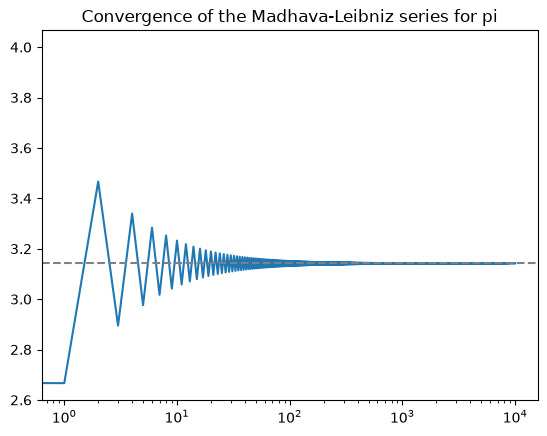

In [19]:
""" Plot the convergence of the series. """

# import the plotting library; give it the shorter name 'plt'
import matplotlib.pyplot as plt

# plot the terms of the series
plt.plot(pi_terms)

# use a log scale on the x-axis
plt.xscale('log')

# plot a horizontal line at the true value of pi
plt.axhline(math.pi, color='gray', linestyle='--')

# set a useful title
plt.title("Convergence of the Madhava-Leibniz series for pi")

# draw the plot
plt.show()

In [20]:
errors = [] # this is for calculating the absolute error for each approximation!

In [21]:
for value in pi_terms: # lets us loop through every approximation
    error = abs(value - math.pi) # calculates the absolute difference between the aprroximation and math.pi
    errors.append(error) # let us store the error so it can be used for plotting

In [22]:
iteration_numbers = range(1, len(pi_terms) + 1) # here I created iteration numbers for the x-axis!

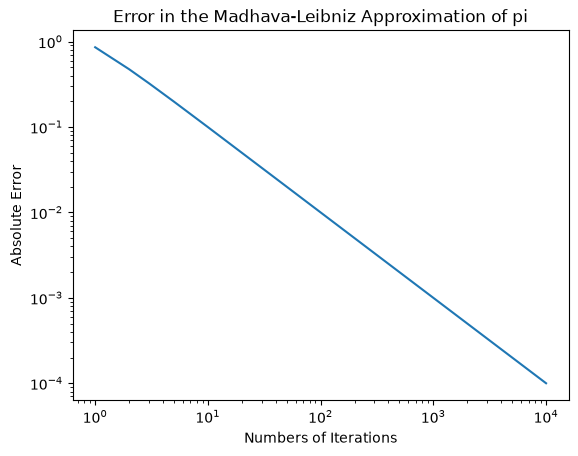

In [23]:
plt.plot(iteration_numbers, errors)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Numbers of Iterations")
plt.ylabel("Absolute Error")
plt.title("Error in the Madhava-Leibniz Approximation of pi")
plt.show()

In [24]:
reasonable_accuracy = 0.001

In [25]:
iterations_needed = None

In [26]:
for i in range(len(errors)): # checks each stored error in order starting with the first 
    if errors[i] < reasonable_accuracy: # let us test whether the current absolute error is below our reasonable accuracy
        iterations_needed = i + 1 # add one because Python lists at zero while my iteration counts begin at one
        break # makes it stop searching after finding the first iteration that meets the requirement for the code

In [27]:
print("Iterations Needed:", iterations_needed)
print("Absolute Error", errors[iterations_needed - 1])
print("Aprroximation of pi", pi_terms[iterations_needed - 1])

Iterations Needed: 1000
Absolute Error 0.000999999749998981
Aprroximation of pi 3.140592653839794


In [28]:
def calculate_pi(N):
    """
    Calculate an approximation of pi using N terms of the Madhava-Leibniz series.
    """
    pi = 0 # start the summation at zero 
    for n in range(1, N + 1): # repeat calculation for n terms
        if n == 1: # first term is one 
            term = 1
        else:
            term = -((-1)**n) / (2*n - 1) # calculate the next alternating term in the series
        pi = pi + term # ad
    pi = 4 * pi
    return pi     

In [29]:
print("10:", calculate_pi(10))
print("100:", calculate_pi(100))
print("1000:", calculate_pi(1000))
print("pi:", math.pi)

10: 3.0418396189294032
100: 3.1315929035585537
1000: 3.140592653839794
pi: 3.141592653589793


Functions are useful when developing scientific code because they can allow for a caculation to be reused but now without having to rewrite the same code each time. In addition, functions make it easier to change, organize, and test a caculation because the code is all contained in one place.

1. For this assignment, I used the Madhava-Leibniz series to appoximate the value of pi. I did this by modifying the original example by storing the approximation at each iteration and calculating its absolute error compared to that of math.pi and by examining how the error has changed as the number of iterations increased.

2. I learned that the approximation became more accurate as the number of iterations increased. As with 10 iterations, my approximation was 3.04184 while for 1,000 iterations it was 3.14059. Therefore, increasing the iterations goes toward the correct value of pi slowly with each iteration.

3. My figure shows that the absolute error decreases as the number of iterations increases. And since both axes are shown on a logarithmic scale, the downward trend shows that there is a good relationship between the increasing iterations and decreasing absolute error as the calcultion is going toward pi.

4. I believe that more iterations will definitly improve the accuracy of the approximation but we also have to realize that each iteration required more computation. For me, I used a reasonable accuracy of an absolute error below 0.001. And with my calculations, I only need 1,000 iterations to reach my reasonable accuracy. Beyound this, yes more iterations will increase the accuracy but I believe there is a point where trying to get the true value of pi after more and more computation is not needed.

5.  For this assignment, I gained a better understanding of using "for" loops and functions. As this assignment allowed me to repeatly calculate terms in the series and analyze the error for many iterations. Also creating a function showed me how a calculation can be used as reasonable code that can be tested using different values.

6. I believe what was challenging for me in this assignment was when I had to debug the code and I got a syntax error in my function. Where I had actually messed up on my parentheses and I was able to correct the expression (and other resulting code) and fix my function. In addition, to conceptual learning about for loops and functions.  